# X controller: reinforcement learning (SAC) to land at a different position

**Advanced task 2: make the drone land at a different position (move along x).** The policy is trained
**only on the model we identified** in `6_identification_x.ipynb` (never on `quadcopter_model.p`).

Same plan as for the yaw: the altitude policy (`models/sac_nn.zip`) keeps the collective thrust `u_T`,
the yaw policy (`models/sac_yaw.zip`) can hold the heading, and a **third**, independent SAC policy
controls the differential command `u_x` on motors 1 and 3:

```
 altitude policy --- u_T ----+
 yaw policy ------- u_yaw ---+--> mixer:  U = u_T + u_yaw [1 -1 1 -1] + u_x [-1 0 1 0]  --> 4 motors
 x policy --------- u_x -----+            (thrust has priority, then yaw, then x)

            +---------- identified pitch model (Python) ----------+
 u_x -----> | NN  w_dot_y[k+1] = F(w_dot_y[k], u_x[k], u_T[k])     | -> wy -> theta -> ax = T sin(theta) -> vx -> x
 u_T -----> |                                                     |                     ^ T = az + g (altitude NN)
            +-----------------------------------------------------+
```

The difference with the yaw is the **length of the chain**: four integrators between the command and
the position, no restoring torque, no damping, no drag (notebook 6). Open loop the drone never comes
back level by itself; the controller has to tilt it, accelerate, tilt it back, brake, and level it.

| choice | what | why |
|---|---|---|
| plant | pitch NN of notebook 6, **randomised**; thrust from the altitude NN | free-run error 0.004 rad/s^2, position error 1.2 cm over 2 s; model C (tanh) kept as an independent test drone and for the PD baseline |
| algorithm | **SAC**, $\gamma = 0.99$ | as for the altitude and the yaw, but a longer horizon (~5 s instead of ~2.5 s): with four integrators the braking starts long before the target (section 3) |
| action | `u_x` itself, in [-0.02, 0.02] | the range where the network and model C agree (beyond, the data has no settled pulse); 0.02 already tilts the drone by 0.3 rad in 0.5 s |
| observation | position error, `vx`, tilt (gyro + accelerometer filter), `wy`, `w_dot_y_prev`, `u_x_prev`, error integral, `u_T` | the state of the chain with its delay (Markov); `theta` estimated because the simulator's `theta` output is noise; `u_T` because the gain and the push depend on it |
| reward | tracking + precision + small tilt + smooth command | section 2.3 |
| robustness | domain randomisation: pitch and thrust models, thrust profile, references, initial speed and tilt, process and sensor noise | model -> simulator gap |

All the code of the environment is in `x_env.py`; this notebook explains it, trains, evaluates and exports.

## 0. Setup

In [ ]:
import os, numpy as np, matplotlib.pyplot as plt, torch
torch.set_num_threads(1)
from stable_baselines3 import SAC
from x_env import (XEnv, XPD, rollout, x_mission, random_x_mission, random_thrust, hover_thrust,
                   load_x_plant, load_x_test_plant,
                   Ts, N_STEPS, X_MAX, U_HOVER, T_MOVE, X_LAND, OBS_NAMES)
np.set_printoptions(suppress=True, precision=4)
os.makedirs('figures', exist_ok=True)
C_SAC, C_PD, C_REF, C_MUTED = '#2a78d6', '#eb6834', '#52514e', '#8a8984'
BASE_NOISE = {'x': 0.005, 'vx': 0.005, 'wy': 0.005, 'w': 0.005,   # about g_noise = 0.1 (10x notebook 6)
              'ax': 0.005, 'az': 0.005}

## 1. The plants: our identified pitch models

**Training plant - pitch NN** (`models/x_model_nn.joblib`): $\dot w_y[k+1] = F(\dot w_y[k], u_x[k], u_T[k])$,
MLP 3 -> 16 tanh -> 1, run in numpy by `x_env.XNNPlant`; `u_T` clipped to the identified [0.2, 0.7].

**Test drone - model C**: $\dot w_y[k+1] = a\,\dot w_y[k] + b\,[\tanh(\beta(u_T+u_x)) - \tanh(\beta(u_T-u_x))] + c$,
identified independently by least squares; its gain linearised at $u_x = 0$ is what the PD inverts.

The right figure is the open-loop response to a short pulse: the tilt stays, the speed keeps growing.
Everything the controller does is "tilt, then tilt back at the right time".

model C: tau = 0.200 s, gain at hover = 172.8 rad/s^2 per unit of u_x


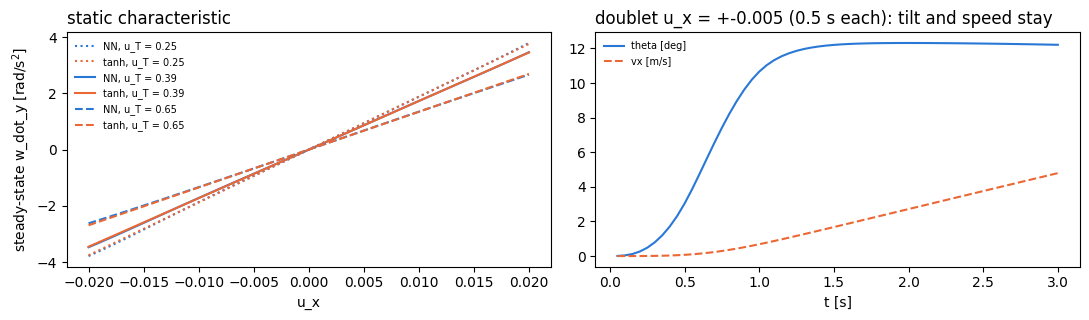

In [2]:
nn_p, tanh_p = load_x_plant(), load_x_test_plant()
print(f'model C: tau = {tanh_p.tau:.3f} s, gain at hover = {tanh_p.gain(U_HOVER):.1f} rad/s^2 per unit of u_x')

fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
ug = np.linspace(-X_MAX, X_MAX, 41)
for uT, ls in ((0.25, ':'), (U_HOVER, '-'), (0.65, '--')):
    for p, c in ((nn_p, C_SAC), (tanh_p, C_PD)):
        st = []
        for u in ug:
            p.reset()
            for _ in range(100): p.step(u, uT)
            st.append(p.w)
        ax[0].plot(ug, st, ls, color=c, label=f'{"NN" if p is nn_p else "tanh"}, u_T = {uT:.2f}')
ax[0].set_xlabel('u_x'); ax[0].set_ylabel('steady-state w_dot_y [rad/s$^2$]'); ax[0].legend(fontsize=7, frameon=False)
ax[0].set_title('static characteristic', loc='left')
env = XEnv(plant=nn_p, thrust=np.full(N_STEPS + 1, U_HOVER))
env.reset(seed=0)
th, vx = [], []
for k in range(60):
    env.step(np.array([0.005 if k < 10 else (-0.005 if k < 20 else 0.0)], dtype=np.float32))
    th.append(env.theta); vx.append(env.vx)
tt = np.arange(1, 61) * Ts
ax[1].plot(tt, np.degrees(th), color=C_SAC, label='theta [deg]'); ax[1].plot(tt, vx, '--', color=C_PD, label='vx [m/s]')
ax[1].set_xlabel('t [s]'); ax[1].set_title('doublet u_x = +-0.005 (0.5 s each): tilt and speed stay', loc='left')
ax[1].legend(fontsize=7, frameon=False); plt.tight_layout(); plt.show()

## 2. The environment (`x_env.XEnv`)

### 2.1 Mission, timing, thrust
**11 s** (`N_STEPS = 220`): 0-1 s on the platform, 1-2 s climb to 0.5 m, **move to x = 1 m from
t = 2 s**, landing from 7 s on the ground at x = 1 m (the altitude part is the altitude policy's job;
here only `x_ref` matters: 0 until 2 s, then 1 m).

Measurements, chosen like the other loops: `x`, `vx`, `wy` sampled at $t_k$; `w_dot_y_prev`, `ax_prev`,
`az_prev` and `u_x_prev` through Unit Delays; `u_T` is the thrust of the altitude policy at the same step.
Kinematics: trapezoid rule for `wy` and `theta` (checked in notebook 6), the same exact-for-linear
rule as `drone_env.py` for `x`. The push is $a_x = T\sin\theta$ with $T = a_z + g$ from the altitude
NN driven by the same `u_T`: during take-off and landing the thrust changes, and so does the push.

**Thrust seen by the x policy**: as for the yaw, a random staircase in training (70 % near hover), hover
in evaluation. **Mixer**: the action is clipped to the margin $1 - |u_T|$.

### 2.2 Observation (identical in MATLAB later)
$$o = [\,e,\ v_x/2,\ \hat\theta/0.3,\ w_y,\ \dot w_{y,prev}/5,\ u_{x,prev}/0.02,\ I/I_{max},\ u_T\,],\qquad
e = x_{ref} - x\ (\text{clipped } \pm 2)$$
The simulator's `theta` is noise, so $\hat\theta$ is computed **inside the observer** by a complementary
filter (`x_env.TiltEstimator`, a persistent variable in MATLAB):
$$\hat\theta_{k-1} \leftarrow a\,\hat\theta_{k-1} + (1-a)\,\mathrm{atan2}(a_{x,prev},\ a_{z,prev}+g),\qquad
\hat\theta_k = \hat\theta_{k-1} + T_s\,(w_{y,k-1} + w_{y,k})/2,\qquad a = e^{-T_s/1\,\mathrm{s}}$$
- the **gyro** integral is exact over a manoeuvre but integrates the noise of `wy`: a random walk. With
  0.005 rad/s of noise the first version (gyro only) landed up to 12 cm off target in the full mission;
- the **accelerometer** gives the tilt without drift, $\tan\theta = a_x/(a_z+g)$ (the tilted-thrust law
  of notebook 6), noisy but with no memory; it corrects the estimate with a 1 s time constant, only when
  there is thrust ($a_z + g > 2$ m/s^2: motors off, $a_x/(a_z+g)$ is meaningless).

The policy was trained with the gyro-only estimate (the filter came after, from the full-mission test):
it now receives a strictly more accurate tilt. No absolute position: the dynamics do not depend on it.

### 2.3 Reward (per step)
$$r = 1 - |e|/2 - 0.5\,(1-e^{-(e/0.05)^2}) - 2\,\theta^2 - 0.2\,(\Delta u_x/0.02)^2$$
- alive bonus + tracking, and a Gaussian term for *precision* (within ~5 cm);
- $\theta^2$: no violent tilt (at 0.3 rad the penalty is 0.18 per step, the size of being 36 cm off);
- $\Delta u_x^2$: smooth command (0.2, as for the yaw);
- termination with -50 if $|\theta| > 0.6$ rad (outside the identified envelope) or $|e| > 4$ m.

### 2.4 Domain randomisation (training only)
| what | range |
|---|---|
| time constant (speed of the motors) | x [0.8, 1.25] (pitch and thrust models) |
| pitch authority (gain) / thrust gain | x [0.85, 1.15] |
| residual torque / hover offset | +-0.05 rad/s^2 / +-0.4 m/s^2 |
| process noise on `w_dot_y` | std up to 0.02 rad/s^2 |
| sensor noise `x` / `vx` / `wy` / `w_dot_y` / `ax` / `az` | std up to 0.01 m / 0.05 m/s / 0.02 rad/s / 0.2 rad/s^2 / 0.05 / 0.3 m/s^2 |
| references | 40 % the mission, 60 % random staircases (steps of 0.3 to 1.5 m, either direction) |
| thrust | random staircase |
| initial state | 30 % already moving (`vx` in +-0.5 m/s) and tilted (+-0.1 rad) |

observation : {'e': np.float32(0.0), 'vx/2': np.float32(0.0), 'theta/TH_MAX': np.float32(0.0), 'wy': np.float32(0.0), 'w_dot_y_prev/5': np.float32(0.0), 'u_x_prev/X_MAX': np.float32(0.0), 'I/I_MAX': np.float32(0.0), 'u_T': np.float32(0.0)}
measurements: {'t': 0.0, 'x': 0.0, 'vx': 0.0, 'wy': 0.0, 'w_dot_y_prev': 0.0, 'ax_prev': 0.0, 'az_prev': 0.0, 'u_x_prev': 0.0, 'u_T': 0.0, 'x_ref': 0.0}


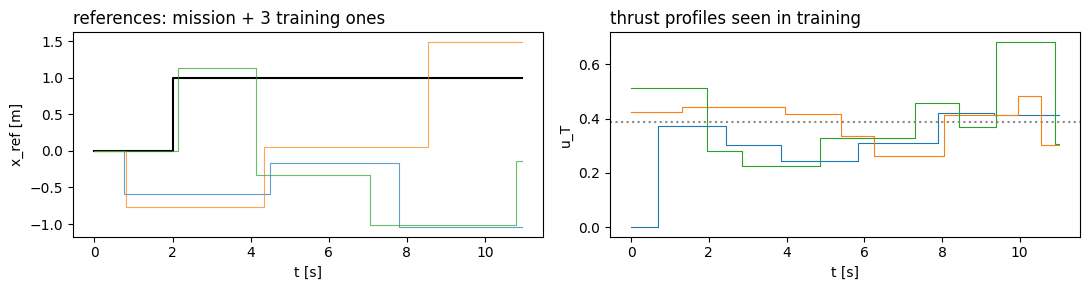

In [3]:
env = XEnv(plant=nn_p)
obs, info = env.reset(seed=0)
print('observation :', dict(zip(OBS_NAMES, obs.round(3))))
print('measurements:', {k: round(v, 3) for k, v in info['m'].items()})

rng = np.random.default_rng(3)
tt = np.arange(N_STEPS) * Ts
fig, ax = plt.subplots(1, 2, figsize=(11, 3))
ax[0].step(tt, [x_mission(t) for t in tt], where='post', color='k', label='mission')
for j in range(3):
    f = random_x_mission(rng); ax[0].step(tt, [f(t) for t in tt], where='post', lw=.8, alpha=.7)
ax[0].set_ylabel('x_ref [m]'); ax[0].set_xlabel('t [s]'); ax[0].set_title('references: mission + 3 training ones', loc='left')
for j in range(3):
    ax[1].step(np.arange(N_STEPS + 1) * Ts, random_thrust(rng), where='post', lw=.8)
ax[1].axhline(U_HOVER, color=C_MUTED, ls=':'); ax[1].set_ylabel('u_T'); ax[1].set_xlabel('t [s]')
ax[1].set_title('thrust profiles seen in training', loc='left'); plt.tight_layout(); plt.show()

### 2.5 Linear baseline: cascade PD
Two nested loops, the classic structure for a quadrotor:
- **outer (position)**: $a_{x,cmd} = K_p e - K_d v_x$, $\theta_{cmd} = \arctan(a_{x,cmd}/g)$ clipped to 0.25 rad;
- **inner (tilt)**: $\dot w_{y,cmd} = K_\theta(\theta_{cmd} - \hat\theta) - K_w w_y$, then
  $u_x = (\dot w_{y,cmd} - c_0)/G(u_T)$ with $G$ the gain of model C at the current thrust.

Gains grid-searched on both models (settling to 5 cm, overshoot): $K_p = 1,\ K_d = 1.5,\ K_\theta = 30,\
K_w = 12$, no integral (it winds up during the 1 m move and doubles the overshoot). Same measurements as
the policy, same $\hat\theta$ (the same `TiltEstimator`).

In [4]:
def pd_controller():
    pd = XPD()
    def c(obs, m):
        if m['t'] == 0:
            pd.reset()
        return pd(m)
    return c

o = rollout(XEnv(plant=nn_p), pd_controller())
print(f"PD on the NN model: RMSE {o['rmse']:.3f} m, settling (5 cm) {o['settle_s']:.2f} s, "
      f"overshoot {o['overshoot_cm']:.1f} cm, max tilt {o['max_tilt_deg']:.1f} deg")

PD on the NN model: RMSE 0.332 m, settling (5 cm) 2.55 s, overshoot 4.6 cm, max tilt 6.2 deg

## 3. Training (SAC)

Same hyper-parameters as the altitude and yaw policies except the discount (`train_sac_x.py` is the
terminal version: `python train_sac_x.py 300000 <seed> [gamma] [du_weight]`). `EvalCallback` evaluates
every 10 k steps on **perturbed models + noise** on the move mission and keeps the best return.

**What happened.** A first run with the yaw settings ($\gamma = 0.98$, smoothness 0.05,
`runs/sac_x_g0.98_du0.05_s0`) stalled for 80 k steps at a policy that reached ~1 m but floated around it
(11 cm of final error), while the PD scored 171 on the *same* reward against 110: the reward was fine,
the learning was not. $\gamma = 0.98$ is a horizon of ~2.5 s; with four integrators the drone must start
braking well before the target, a consequence the policy barely sees. A second run with $\gamma = 0.99$
(~5 s) and smoothness 0.2 (`runs/sac_x_s0`) learned faster: at 60 k steps it moved with 0.6 cm of
overshoot. Both were stopped once the evaluation return oscillated without trend (180 k and 110 k steps).

**Which checkpoint.** The evaluation return (20 perturbed, noisy flights) is a noisy selector: later
"best" checkpoints of both runs had a higher return but a slower, more overshooting move. Every new best
was therefore archived (`runs/<run>/best_<steps>.zip`) and the candidates compared on the mission
metrics, on the tanh drone and on 100 perturbed drones (numbers at selection time, with the gyro-only tilt
estimate of the first version; the tables of section 4 are the final word):

| checkpoint | nominal: settle / overshoot / final | 100 drones: settle / overshoot / final, unsettled |
|---|---|---|
| $\gamma$ 0.98, 150 k | 6.10 s / 11.0 cm / 1.48 cm | 6.20 s / 11.1 cm / 1.78 cm, 3 |
| **$\gamma$ 0.99, 60 k** (kept) | **4.00 s / 0.6 cm / 0.51 cm** | **4.65 s / 2.1 cm / 2.95 cm**, 26 |
| $\gamma$ 0.99, 110 k | 6.15 s / 6.8 cm / 2.39 cm | 6.30 s / 6.9 cm / 2.35 cm, 10 |
| PD | 2.55 s / 4.6 cm / 0.07 cm | 4.00 s / 4.5 cm / 3.51 cm, 38 |

The landing starts 5 s after the move: only the 60 k checkpoint settles before it on most drones.

`TRAIN = False` loads `models/sac_x.zip` if it exists (otherwise it trains and keeps the best return).

In [5]:
TRAIN = not os.path.isfile('models/sac_x.zip')
STEPS = 300_000
if TRAIN:
    import shutil
    from stable_baselines3.common.monitor import Monitor
    from stable_baselines3.common.callbacks import EvalCallback
    train_env = Monitor(XEnv(plant=nn_p, randomize=True))
    eval_env = Monitor(XEnv(plant=nn_p, randomize=True, fig_prob=1.0))
    agent = SAC('MlpPolicy', train_env, seed=0, learning_rate=3e-4, buffer_size=300_000, batch_size=256,
                gamma=0.99, tau=0.005, learning_starts=5_000, policy_kwargs=dict(net_arch=[128, 128]),
                tensorboard_log='runs/tb')
    agent.learn(STEPS, tb_log_name='sac_x_s0',
                callback=EvalCallback(eval_env, n_eval_episodes=20, eval_freq=10_000, deterministic=True,
                                      best_model_save_path='runs/sac_x_s0', log_path='runs/sac_x_s0'))
    shutil.copy('runs/sac_x_s0/best_model.zip', 'models/sac_x.zip')
agent = SAC.load('models/sac_x.zip', device='cpu')
print(agent.policy.actor)

Actor(
  (features_extractor): FlattenExtractor(
    (flatten): Flatten(start_dim=1, end_dim=-1)
  )
  (latent_pi): Sequential(
    (0): Linear(in_features=8, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ReLU()
  )
  (mu): Linear(in_features=128, out_features=1, bias=True)
  (log_std): Linear(in_features=128, out_features=1, bias=True)
)


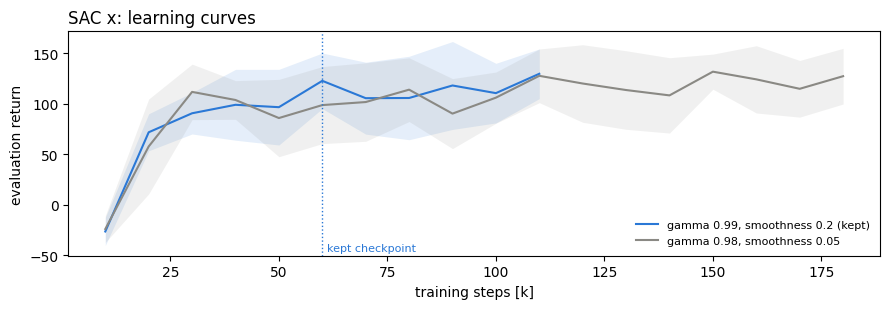

In [6]:
# learning curves (evaluation return on perturbed models + noise, move mission). The returns of the two
# runs are not on the same scale (different smoothness weight): compare the shapes, not the levels.
plt.figure(figsize=(9, 3.2))
for run, c, lab in (('runs/sac_x_s0', C_SAC, 'gamma 0.99, smoothness 0.2 (kept)'),
                    ('runs/sac_x_g0.98_du0.05_s0', C_MUTED, 'gamma 0.98, smoothness 0.05')):
    f = os.path.join(run, 'evaluations.npz')
    if os.path.isfile(f):
        d = np.load(f); m, sd = d['results'].mean(1), d['results'].std(1)
        plt.plot(d['timesteps'] / 1e3, m, color=c, label=lab)
        plt.fill_between(d['timesteps'] / 1e3, m - sd, m + sd, color=c, alpha=.12, lw=0)
plt.axvline(60, color=C_SAC, ls=':', lw=1); plt.text(61, plt.ylim()[0] + 5, 'kept checkpoint', color=C_SAC, fontsize=8)
plt.xlabel('training steps [k]'); plt.ylabel('evaluation return'); plt.legend(frameon=False, fontsize=8)
plt.title('SAC x: learning curves', loc='left'); plt.tight_layout(); plt.show()

## 4. Evaluation

Two flights, SAC against the PD: on the **training model** (the NN, nominal) and on the **tanh model**, which the policy has never seen: the same question as model -> simulator. Robustness to sensor noise is then checked on the real simulator, in MATLAB (`g_noise`).

Metrics: RMSE of the position (dominated by the step itself), **settling time** to within 5 cm for good,
**overshoot**, final error, max tilt, and the rms of $\Delta u_x$ (command smoothness).

In [ ]:
sac_controller = lambda obs, m: float(agent.predict(obs, deterministic=True)[0][0])

def compare(plant, noise=None, thrust=None, seed=0):
    env = XEnv(plant=plant, noise=noise, thrust=thrust)
    return {'SAC': rollout(env, sac_controller, seed), 'PD': rollout(env, pd_controller(), seed)}

cases = [('NN nominal', compare(nn_p)),
         ('tanh (never seen)', compare(tanh_p))]

fig, ax = plt.subplots(4, len(cases), figsize=(4.6 * len(cases), 8.5), sharex=True,
                       gridspec_kw={'height_ratios': [2, 1, 1, 1]}, squeeze=False)
for j, (title, res) in enumerate(cases):
    a = ax[0, j]
    a.step(res['SAC']['t'], res['SAC']['x_ref'], '--', where='post', color=C_REF, lw=1.1, label='reference')
    for k, c in (('PD', C_PD), ('SAC', C_SAC)):
        a.plot(res[k]['t'], res[k]['x'], color=c, label=f"{k}  RMSE {res[k]['rmse']:.3f} m")
    a.set_title(title, loc='left', fontsize=10); a.set_ylabel('x [m]'); a.legend(fontsize=7, frameon=False)
    for k, c in (('PD', C_PD), ('SAC', C_SAC)):
        ax[1, j].step(res[k]['t'], res[k]['u'], where='post', color=c, lw=1)
        ax[2, j].plot(res[k]['t'], np.degrees(res[k]['theta']), color=c, lw=1)
    ax[3, j].step(res['SAC']['t'], res['SAC']['u_T'], where='post', color=C_MUTED)
    ax[1, j].set_ylabel('u_x'); ax[2, j].set_ylabel('theta [deg]'); ax[3, j].set_ylabel('u_T'); ax[3, j].set_xlabel('t [s]')
plt.tight_layout(); plt.savefig('figures/x_flights.png', dpi=150); plt.show()

print(f'{"case":20s} {"":4s} {"RMSE":>7s} {"settle":>7s} {"overshoot":>10s} {"final err":>10s} {"max tilt":>9s} {"du rms":>8s}')
for title, res in cases:
    for k in ('SAC', 'PD'):
        o = res[k]
        print(f"{title:20s} {k:4s} {o['rmse']:6.3f}m {o['settle_s']:6.2f}s {o['overshoot_cm']:8.1f}cm "
              f"{o['final_err_cm']:8.2f}cm {o['max_tilt_deg']:8.1f}d {o['du_rms']:8.5f}")

## 5. Export to MATLAB: the full mission

The x policy flies **with the altitude and yaw policies**, through the mixer. `full_mission_x.py` flies the
full mission on the identified models and writes into `../rl_interface_x/` the three policies
(`policy.mat`, `policy_yaw.mat`, `policy_x.mat`) and the reference flight `traj_full_x.mat`;
`full_mission_follow.py` does the same for following / landing on the vehicle (tracking policy):

```
cd python;  python full_mission_x.py            # land at a different position
            python full_mission_follow.py       # follow the vehicle   (python full_mission_follow.py land: land on it)
```

Then in MATLAB, `rl_interface_x/EINT_RL_eval_x` (or `EINT_RL_eval_follow`, `EINT_RL_eval_land_vehicle`)
checks the controller against Python and flies the mission on the simulator.

## 6. Critical analysis (to complete with the results above)

* **Why this is harder than the yaw.** Four integrators instead of two, and the tilt cannot be measured
  directly: it has to be estimated, and a gyro-only estimate drifts (section 2.2). A pure proportional action on the position is unstable: any
  controller must contain the inner tilt loop, explicitly (the PD cascade) or implicitly (the policy
  sees `theta`, `wy` and the motor state).
* **Where RL can win.** The move is "tilt, accelerate, tilt back, brake, level": a bang-bang-like profile
  under a tilt limit. The cascade PD reacts linearly; the policy can plan the reversal earlier and use
  the full tilt budget. Compare settling times at equal overshoot (section 4).
* **Transfer.** The tanh flight is the honest check before `UAV_model.slx`.
* **Training is the fragile part.** The discount had to be raised for the longer chain, and the
  checkpoint chosen by the evaluation return was not the best mover: with RL, *what* is selected
  (the metric) matters as much as how long it trains.
* **Coupling.** Notebook 6: the tilt costs $\approx g\theta^2/2$ of vertical acceleration (0.2 m/s^2 at
  0.2 rad), inside the +-0.4 m/s^2 the altitude policy was trained for, and $u_x$ produces a small yaw
  torque ($\propto u_x^2$) that the yaw policy holds. Both appear in `full_mission_x.py`.
* **Limits.** The model is valid for `u_T` in [0.2, 0.7], `|u_x| <= 0.02`, `|theta| <~ 0.5` rad. The
  heading must stay near 0 during the move: if the drone has turned, `u_x` pushes it along its own
  axis, not along the world x (a rotation of the command by `psi` would be the fix).